
# California House Price Prediction Using Machine Learning

## Project Overview

This project predicts median house values using the California Housing dataset. It explores the dataset, visualizes important relationships, trains machine learning models, and compares their performance.

## Objectives

- Explore and visualize the housing dataset.
- Build a Linear Regression model as a baseline.
- Train a Random Forest regression model.
- Evaluate both models using MAE, MSE, RMSE, and R² score.
- Save the best-performing model for future predictions.


In [1]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Convert the dataset into a DataFrame
df = housing.frame

# Display the first five rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Display summary statistics
print("\nSummary statistics:")
df.describe()


Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Summary statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


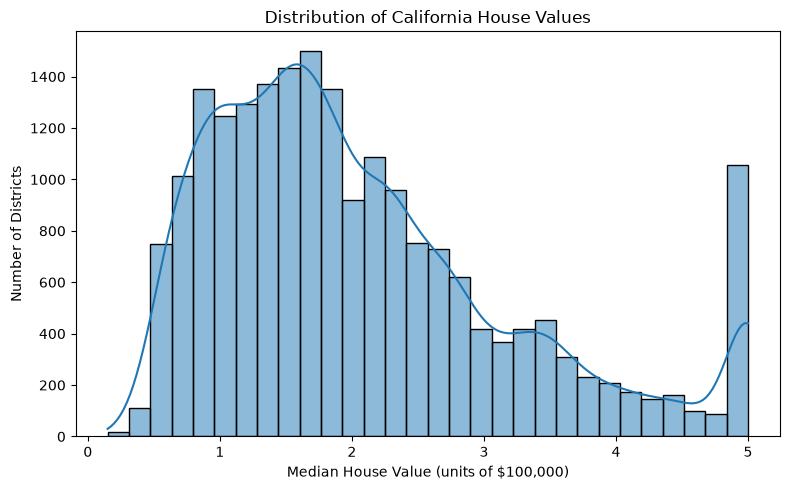

In [3]:

# Plot the distribution of median house values
plt.figure(figsize=(8, 5))

sns.histplot(df["MedHouseVal"], bins=30, kde=True)

plt.title("Distribution of California House Values")
plt.xlabel("Median House Value (units of $100,000)")
plt.ylabel("Number of Districts")

plt.tight_layout()
plt.show()


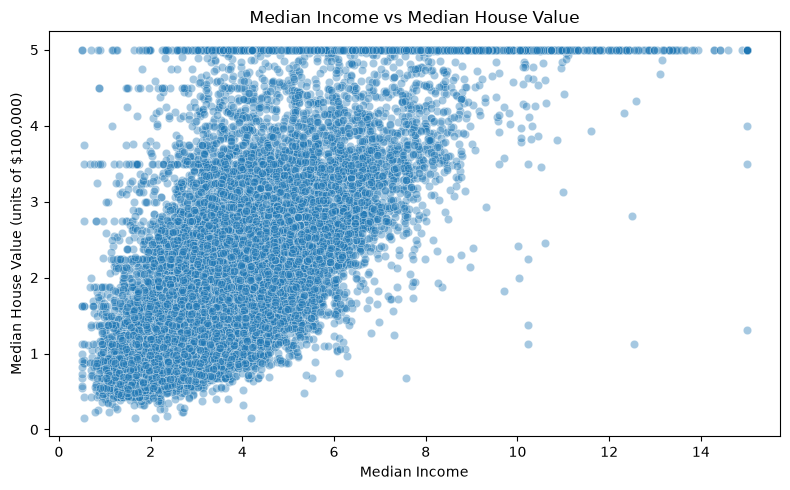

In [4]:

# Plot median income against median house value
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.4
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (units of $100,000)")

plt.tight_layout()
plt.show()


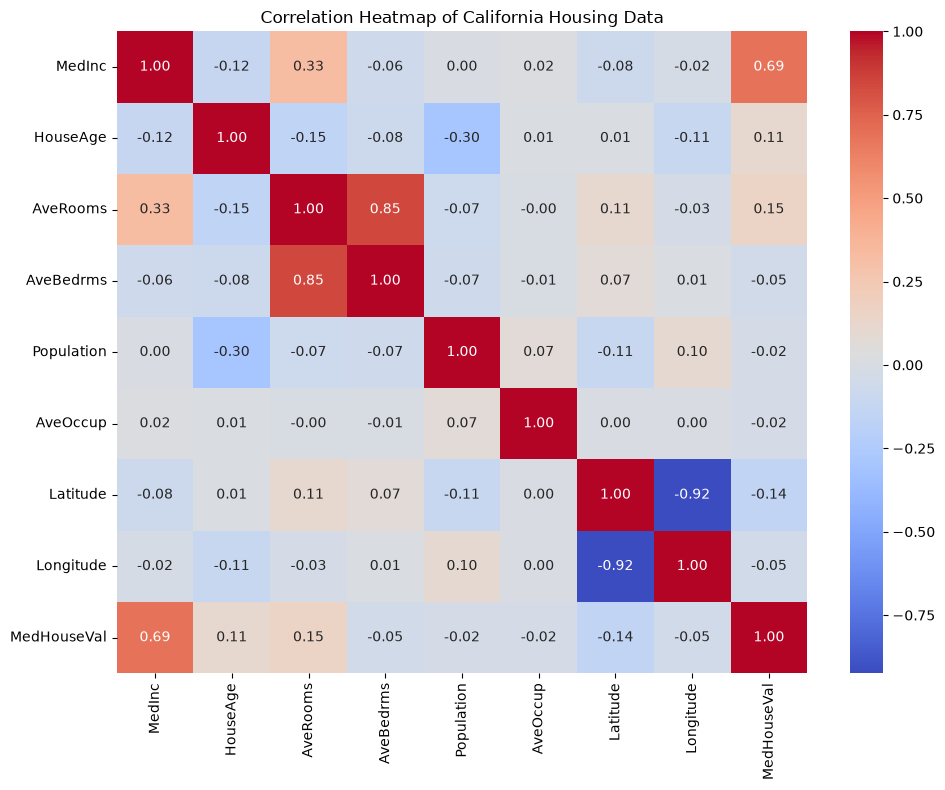

In [5]:

# Calculate correlations between numerical columns
correlation = df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of California Housing Data")
plt.tight_layout()
plt.show()


In [6]:

# Separate input features (X) and target variable (y)
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)


Input features shape: (20640, 8)
Target shape: (20640,)


In [7]:

from sklearn.model_selection import train_test_split

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training data shape: (16512, 8)
Testing data shape: (4128, 8)
Training target shape: (16512,)
Testing target shape: (4128,)


In [8]:

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [9]:

# Predict house values using the testing data
y_pred = model.predict(X_test)

print("First 10 actual house values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted house values:")
print(y_pred[:10])


First 10 actual house values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 predicted house values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print("--- Linear Regression Evaluation Results ---")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

print("MAE in dollars: $", round(mae * 100000, 2))
print("RMSE in dollars: $", round(rmse * 100000, 2))


--- Linear Regression Evaluation Results ---
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R² Score: 0.5758
MAE in dollars: $ 53320.01
RMSE in dollars: $ 74558.14


In [11]:

from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [12]:

# Predict house values using Random Forest
rf_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("--- Random Forest Evaluation Results ---")
print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R² Score:", round(rf_r2, 4))

print("MAE in dollars: $", round(rf_mae * 100000, 2))
print("RMSE in dollars: $", round(rf_rmse * 100000, 2))


--- Random Forest Evaluation Results ---
MAE: 0.3277
MSE: 0.256
RMSE: 0.506
R² Score: 0.8046
MAE in dollars: $ 32773.11
RMSE in dollars: $ 50598.6


In [13]:

# Compare Linear Regression and Random Forest
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print("Model Comparison:")
display(comparison.round(4))


Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.5332,0.5559,0.7456,0.5758
1,Random Forest,0.3277,0.2560,0.5060,0.8046


In [14]:

import pickle

# Save the trained Random Forest model
with open("best_house_price_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [15]:

# Load the saved model
with open("best_house_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

# Select one example from the test dataset
sample_house = X_test.iloc[[0]]

# Predict the house value
predicted_value = loaded_model.predict(sample_house)[0]

print("Predicted house value:", round(predicted_value, 4))
print("Predicted value in dollars: $", round(predicted_value * 100000, 2))


Predicted house value: 0.5081
Predicted value in dollars: $ 50809.0



## Conclusion

This project used the California Housing dataset to predict median house values using machine learning.

### Models Developed
- **Linear Regression:** Used as the baseline model.
- **Random Forest Regressor:** Used to capture more complex relationships in the dataset.

### Results
The Random Forest model performed better than Linear Regression on the test dataset, achieving a higher R² score and lower prediction errors.

### Key Learnings
- Explored the dataset using Pandas.
- Visualized data distributions and relationships using Matplotlib and Seaborn.
- Split the dataset into training and testing sets.
- Trained and evaluated regression models using MAE, MSE, RMSE, and R².
- Saved and reloaded the trained model using Pickle.

### Limitations and Future Improvements
- The dataset's target values are capped, which limits predictions for higher-priced areas.
- Hyperparameter tuning and cross-validation could improve model evaluation.
- Additional features and newer housing data could be explored.
- Model predictions should not be treated as guaranteed real-world market prices.
